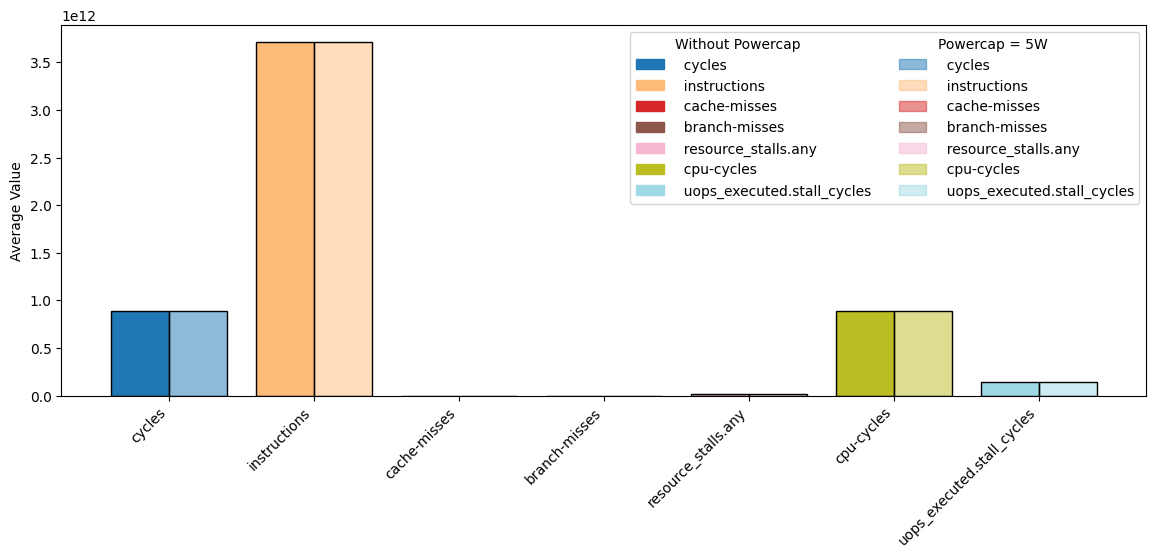

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from matplotlib.colors import to_rgba

# Load CSV
df_perf = pd.read_csv("../csv_files/perf_stats.csv")

# Select all numeric columns except Powercap
numeric_cols = df_perf.select_dtypes(include='number').columns.tolist()
numeric_cols.remove('Powercap')

# Colors for all columns
base_colors = plt.cm.tab20(np.linspace(0, 1, len(numeric_cols)))

powercaps = sorted(df_perf['Powercap'].unique())

# Group by Powercap and compute mean
df_grouped = df_perf.groupby('Powercap')[numeric_cols].mean().reset_index()

# Barplot parameters
bar_width = 0.8 / len(powercaps)
x = np.arange(len(numeric_cols))

plt.figure(figsize=(14,7))

for i, pc in enumerate(powercaps):
    values = df_grouped[df_grouped['Powercap'] == pc][numeric_cols].values.flatten()
    positions = x - 0.4 + i * bar_width + bar_width/2
    
    # Make Powercap bars lighter
    if pc == -1:
        colors = base_colors
    else:
        # Reduce alpha to 0.5 for lighter effect
        colors = [to_rgba(c, alpha=0.5) for c in base_colors]
    
    plt.bar(positions, values, width=bar_width, color=colors, edgecolor='black')

plt.xticks(x, numeric_cols, rotation=45, ha='right')
plt.ylabel('Average Value')

# Build legend in patches style
patches = []
for pc in powercaps:
    label_group = "Without Powercap" if pc == -1 else f"Powercap = {pc}W"
    patches.append(mpatches.Patch(color='none', label=label_group))  # Group title
    for i, col in enumerate(numeric_cols):
        color_patch = base_colors[i] if pc == -1 else to_rgba(base_colors[i], alpha=0.5)
        patches.append(mpatches.Patch(color=color_patch, label=f"  {col}"))

# Legend in top-right corner
plt.legend(
    handles=patches,
    frameon=True,
    loc='upper right',
    bbox_to_anchor=(1.0, 1.0),
    fontsize=10,
    ncol=2
)

plt.subplots_adjust(bottom=0.35)
#plt.savefig("perf.pdf", format='pdf', bbox_inches='tight')
plt.show()
